# Week 4 - Logistic Regression and Feature Scaling
## Dataset: NOAA Storm Events

This week covers logistic regression and feature scaling. For Storm Events the yes or no question is whether a 2017 event had any property damage reported. Property damage is extremely right-skewed, with most events at zero, so predicting whether any damage occurred is a better fit for logistic regression than predicting the dollar amount.

Logistic regression starts from what the lesson calls LINEXP, the linear combination $\text{LINEXP} = \beta_0 + \sum_i \beta_i X_i$. It treats LINEXP as the log-odds of damage and turns it into a probability with the logistic function $p = \dfrac{1}{1 + e^{-\text{LINEXP}}}$, which always stays between 0 and 1. The coefficients are chosen to minimize cross-entropy loss, with a Lasso or Ridge penalty added when needed.

Storm Events has a built-in version of the lesson's point about independent samples, because events are grouped into episodes. A single storm system can produce dozens of reports across neighboring counties, and those reports share the same weather and often the same damage label. A good part of this notebook is about what that does to the model, along with how scaling affects the solver and the penalty, and what multicollinearity looks like when the features include event-type indicators.

In [1]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import (train_test_split, GroupShuffleSplit, GroupKFold,
                                     GridSearchCV, validation_curve)
from sklearn.preprocessing import (StandardScaler, MinMaxScaler, RobustScaler,
                                   SplineTransformer, OneHotEncoder)
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, roc_auc_score,
                             log_loss, ConfusionMatrixDisplay)
from sklearn.exceptions import ConvergenceWarning

warnings.filterwarnings('ignore', category=FutureWarning)


def fit_quietly(model, X, y):
    """Fit a model and report whether the solver hit its iteration limit."""
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always', ConvergenceWarning)
        t0 = time.time()
        model.fit(X, y)
        seconds = time.time() - t0
    hit_limit = any(issubclass(w.category, ConvergenceWarning) for w in caught)
    return seconds, hit_limit


def scores(name, y_true, prob, threshold=0.5):
    pred = (prob >= threshold).astype(int)
    return {'Model': name,
            'Accuracy': accuracy_score(y_true, pred),
            'Balanced acc.': balanced_accuracy_score(y_true, pred),
            'F1': f1_score(y_true, pred),
            'Log loss': log_loss(y_true, np.clip(prob, 1e-6, 1 - 1e-6)),
            'ROC-AUC': roc_auc_score(y_true, prob)}

df = pd.read_csv('StormEvents_details-ftp_v1.0_d2017_c20260519.csv', low_memory=False)

def parse_damage(val):
    if pd.isna(val):
        return np.nan
    val = str(val).strip().upper()
    mult = {'K': 1e3, 'M': 1e6, 'B': 1e9}
    try:
        return float(val[:-1]) * mult[val[-1]] if val[-1] in mult else float(val)
    except ValueError:
        return np.nan

df['damageProperty'] = df['DAMAGE_PROPERTY'].apply(parse_damage)
print('All 2017 events:', len(df))

All 2017 events: 57041


### Target and features

The target is `damaged`, which equals 1 when the parsed `DAMAGE_PROPERTY` value is above zero. Events with no damage value or no starting latitude and longitude are dropped. The second filter removes most zone-based events such as high wind, winter weather, and drought, which are reported for forecast zones instead of points, so this model covers point-located events like thunderstorm wind, hail, floods, and tornadoes.

The features are starting latitude and longitude, month, event duration, and indicators for the eight most common event types (thunderstorm wind, hail, flash flood, flood, tornado, marine thunderstorm wind, heavy rain, and lightning). The remaining 2% of events, mostly funnel clouds, debris flows, and waterspouts, form the baseline group. Duration is measured in hours and runs from 0 to almost 744 (about a month), with a mean of 5 and a standard deviation of 41. More than half of events have the same start and end time, so I log-transformed duration after adding 0.1 hours.

In [2]:
data = df.dropna(subset=['damageProperty', 'BEGIN_LAT', 'BEGIN_LON']).copy()
data['damaged'] = (data['damageProperty'] > 0).astype(int)
begin = pd.to_datetime(data['BEGIN_DATE_TIME'], format='%d-%b-%y %H:%M:%S', errors='coerce')
end = pd.to_datetime(data['END_DATE_TIME'], format='%d-%b-%y %H:%M:%S', errors='coerce')
data['durationHours'] = ((end - begin).dt.total_seconds() / 3600).clip(lower=0)
data['logDuration'] = np.log10(data['durationHours'] + 0.1)
data['month'] = begin.dt.month

top_types = data['EVENT_TYPE'].value_counts().head(8).index
type_cols = []
for t in top_types:
    col = 'type_' + t.replace(' ', '')
    data[col] = (data['EVENT_TYPE'] == t).astype(int)
    type_cols.append(col)
data = data.dropna(subset=['month', 'logDuration']).reset_index(drop=True)

numeric = ['BEGIN_LAT', 'BEGIN_LON', 'month', 'logDuration']
features = numeric + type_cols
print('Rows used:', len(data), '| share with property damage reported:', round(data['damaged'].mean(), 3))
print()
print('Raw scales of the numeric inputs:')
data[['BEGIN_LAT', 'BEGIN_LON', 'month', 'durationHours', 'logDuration']].agg(['mean', 'std', 'min', 'max']).T.round(2)

Rows used: 31863 | share with property damage reported: 0.347

Raw scales of the numeric inputs:


,mean,std,min,max
BEGIN_LAT,37.38,5.12,-14.36,60.47
BEGIN_LON,-91.14,11.56,-170.83,-64.74
month,5.55,2.28,1.00,12.00
durationHours,5.02,41.46,0.00,743.98
logDuration,-0.59,0.71,-1.00,2.87


### Are storm events independent?

The lesson's stock example shows how hundreds of rows can hold only one real example when the rows move together. Storm events have the same structure. Each event belongs to an episode, a single storm system that a forecast office logs as one group, and events in the same episode share the same weather and are often written up by the same people.

To see how much that matters for logistic regression, I bootstrapped the coefficients two ways, once resampling individual events and once resampling whole episodes. If the events were independent, the two would give about the same spread. If they are clustered, resampling episodes will show more spread, because it reflects how much the answer would change with a different set of storms.

Events: 31863 | distinct storm episodes: 5220 | events per episode: 6.1
Multi-event episodes where every event has the same damage label: 0.644



                             SD, resampling events  SD, resampling episodes  Ratio
BEGIN_LAT                                    0.014                    0.047  3.318
BEGIN_LON                                    0.020                    0.045  2.307
month                                        0.016                    0.049  3.107
logDuration                                  0.036                    0.066  1.832
type_ThunderstormWind                        0.140                    0.233  1.660
type_Hail                                    0.150                    0.283  1.887
type_FlashFlood                              0.162                    0.272  1.677
type_Flood                                   0.167                    0.306  1.832
type_Tornado                                 0.153                    0.236  1.543
type_MarineThunderstormWind                  0.456                    0.490  1.075
type_HeavyRain                               0.191                    0.438  2.288
typ

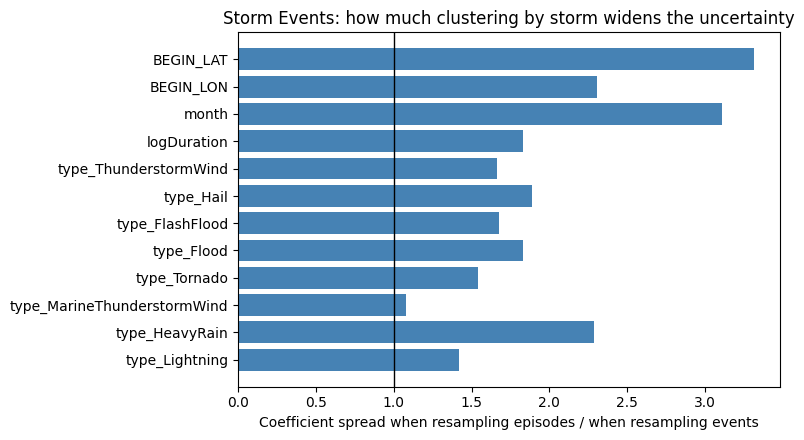

In [3]:
episodes = data.groupby('EPISODE_ID')['damaged'].agg(['mean', 'size'])
multi = episodes[episodes['size'] > 1]
print('Events:', len(data), '| distinct storm episodes:', len(episodes),
      '| events per episode:', round(len(data) / len(episodes), 1))
print('Multi-event episodes where every event has the same damage label:',
      round(((multi['mean'] == 0) | (multi['mean'] == 1)).mean(), 3))

# Bootstrap the coefficients two ways: resampling events, and resampling whole episodes
Xb = np.hstack([StandardScaler().fit_transform(data[numeric]), data[type_cols].values])
yb = data['damaged'].values
episode_rows = pd.Series(np.arange(len(data))).groupby(data['EPISODE_ID'].values).apply(np.array)
rng = np.random.RandomState(0)
event_fits, episode_fits = [], []
for _ in range(100):
    idx = rng.randint(0, len(yb), len(yb))
    event_fits.append(LogisticRegression(max_iter=1000).fit(Xb[idx], yb[idx]).coef_[0])
    pick = rng.choice(len(episode_rows), len(episode_rows), replace=True)
    idx = np.concatenate(episode_rows.iloc[pick].values)
    episode_fits.append(LogisticRegression(max_iter=1000).fit(Xb[idx], yb[idx]).coef_[0])
spread = pd.DataFrame({'SD, resampling events': np.std(event_fits, axis=0),
                       'SD, resampling episodes': np.std(episode_fits, axis=0)}, index=features)
spread['Ratio'] = spread.iloc[:, 1] / spread.iloc[:, 0]
print()
print(spread.round(3).to_string())
design_effect = (spread['Ratio'] ** 2).mean()
print()
print(f'Average variance inflation from clustering: {design_effect:.1f}x, '
      f'so {len(yb):,} events behave like roughly {len(yb) / design_effect:,.0f} independent ones')

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(spread.index, spread['Ratio'], color='steelblue')
ax.axvline(1, color='black', linewidth=1)
ax.set_xlabel('Coefficient spread when resampling episodes / when resampling events')
ax.set_title('Storm Events: how much clustering by storm widens the uncertainty')
ax.invert_yaxis()
plt.tight_layout()
plt.show()

In [4]:
groups = data['EPISODE_ID'].values
y = data['damaged'].values
train_idx, test_idx = next(GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=0).split(data, y, groups))
train, test = data.iloc[train_idx], data.iloc[test_idx]
y_train, y_test = y[train_idx], y[test_idx]
g_train = groups[train_idx]
print('Training events:', len(y_train), '| test events:', len(y_test),
      '| episodes in both:', len(set(g_train) & set(groups[test_idx])))

Training events: 23902 | test events: 7961 | episodes in both: 0


The 31,863 events come from only 5,220 episodes, an average of 6.1 events each, and in 64% of multi-event episodes every event has the same damage label. Resampling episodes widened the coefficient spread for every feature, from 1.1 times for marine thunderstorm wind up to 3.3 times for latitude. Averaged over the features, the variance inflation is 4.4, so for estimating coefficients the data behaves like roughly 7,266 independent events, not 31,863. Latitude and month are hit hardest, which makes sense because every event in an episode shares nearly the same place and date.

That result is why the cell above splits the data by episode. With `GroupShuffleSplit`, all events from a given storm go to either training or testing, never both, so the test score measures how the model does on storms it has not seen. The cross-validation later on uses `GroupKFold` for the same reason.

### Feature scaling and the solver

The lesson gives two reasons to scale features. A gradient-based solver converges faster when features are on similar scales, because a feature in large units dominates each step and causes the solver to overshoot. And a penalty such as Lasso or Ridge only treats features fairly when a one-unit change means something comparable for each of them, which is the point of the milk and steak example.

To test both, I fit the same model five ways, with raw duration in hours or with log duration, left unscaled or standardized, plus min-max scaling for the log version. Each runs at C = 1, a light penalty, and at C = 0.01, a strong one. In scikit-learn, C is the inverse of the lesson's $\lambda$, so a smaller C means more regularization. The solver is L-BFGS, scikit-learn's default, which uses gradients like gradient descent does but also estimates the curvature of the loss.

                     Setup    C  Solver iterations  Hit iteration limit  Fit seconds  Test log loss  Test ROC-AUC
  Raw duration, no scaling 1.00                926                False         1.30         0.5027        0.8133
Raw duration, standardized 1.00                 20                False         0.05         0.5027        0.8137
  Log duration, no scaling 1.00                599                False         0.80         0.4982        0.8211
Log duration, standardized 1.00                 24                False         0.04         0.4982        0.8214
     Log duration, min-max 1.00                 46                False         0.07         0.4981        0.8213
  Raw duration, no scaling 0.01                547                False         0.64         0.5177        0.8007
Raw duration, standardized 0.01                 14                False         0.03         0.5035        0.8129
  Log duration, no scaling 0.01                507                False         0.70    

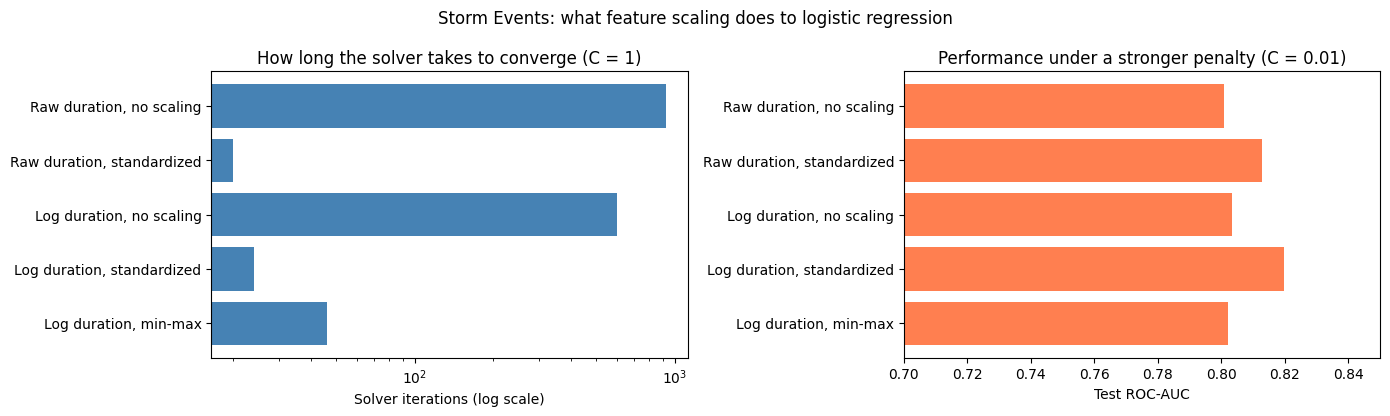

In [5]:
raw_numeric = ['BEGIN_LAT', 'BEGIN_LON', 'month', 'durationHours']
configs = [
    ('Raw duration, no scaling', raw_numeric + type_cols, None),
    ('Raw duration, standardized', raw_numeric + type_cols, StandardScaler),
    ('Log duration, no scaling', features, None),
    ('Log duration, standardized', features, StandardScaler),
    ('Log duration, min-max', features, MinMaxScaler),
]
rows = []
for C in [1.0, 0.01]:
    for name, cols, scaler in configs:
        steps = ([scaler()] if scaler else []) + [LogisticRegression(C=C, max_iter=3000)]
        model = make_pipeline(*steps)
        seconds, hit_limit = fit_quietly(model, train[cols], y_train)
        prob = model.predict_proba(test[cols])[:, 1]
        rows.append({'Setup': name, 'C': C, 'Solver iterations': model[-1].n_iter_[0],
                     'Hit iteration limit': hit_limit, 'Fit seconds': round(seconds, 2),
                     'Test log loss': round(log_loss(y_test, prob), 4),
                     'Test ROC-AUC': round(roc_auc_score(y_test, prob), 4)})
scaling_results = pd.DataFrame(rows)
print(scaling_results.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
weak = scaling_results[scaling_results['C'] == 1.0]
strong = scaling_results[scaling_results['C'] == 0.01]
axes[0].barh(weak['Setup'], weak['Solver iterations'], color='steelblue')
axes[0].set_xscale('log')
axes[0].set_xlabel('Solver iterations (log scale)')
axes[0].set_title('How long the solver takes to converge (C = 1)')
axes[0].invert_yaxis()
axes[1].barh(strong['Setup'], strong['Test ROC-AUC'], color='coral')
axes[1].set_xlim(0.7, 0.85)
axes[1].set_xlabel('Test ROC-AUC')
axes[1].set_title('Performance under a stronger penalty (C = 0.01)')
axes[1].invert_yaxis()
fig.suptitle('Storm Events: what feature scaling does to logistic regression')
plt.tight_layout()
plt.show()

Scaling made the solver much faster. With raw duration and no scaling, L-BFGS needed 926 iterations, and after standardizing it needed 20. With log duration it went from 599 iterations to 24. All of these converged within the 3,000-iteration limit, and at C = 1 the unscaled and standardized versions reached nearly the same answer (a log loss of 0.5027 for raw duration either way and 0.4982 for log duration either way). That is what should happen when the penalty is light.

The strong penalty is where the scalers split apart. At C = 0.01, the standardized log-duration model keeps its ROC-AUC at 0.820, but the unscaled version drops to 0.803 and min-max to 0.802. The min-max case is the milk and steak problem. Latitude runs from -14.4 (American Samoa) to 60.5 (Alaska), so after min-max scaling its standard deviation is only about 0.07, while the event-type indicators keep their full 0 to 1 range. The penalty charges the same price per unit of coefficient, so latitude needs a much larger coefficient to have the same effect, and it gets shrunk the hardest. Standardization gives every numeric feature a standard deviation of 1, so the penalty treats them evenly.

The log transform helped on its own too, raising ROC-AUC from 0.813 to 0.821 at C = 1. Most events last minutes or less, but a few run for weeks, and on the raw scale those few set the slope.

### Multicollinearity and the logistic curve

The lesson warns that logistic regression struggles with correlated features the same way linear regression does. The numeric features here are nearly unrelated, but the event-type indicators overlap by construction, since each event has exactly one type and the eight types cover 98% of the data. The next cell checks the variance inflation factors (VIFs), then fits the model with standardized numeric features and 0/1 event-type indicators and plots each test event's LINEXP against the logistic curve. It also lists the test events with the largest cross-entropy loss, which for one event is $-\log(\hat p)$ if damage was reported and $-\log(1 - \hat p)$ if it was not.

Variance inflation factors:
type_ThunderstormWind          12.08
type_Hail                       9.46
type_FlashFlood                 6.10
type_Flood                      4.92
logDuration                     3.13
type_MarineThunderstormWind     2.97
type_Tornado                    2.93
type_HeavyRain                  2.80
type_Lightning                  1.51
BEGIN_LAT                       1.13
BEGIN_LON                       1.11
month                           1.08


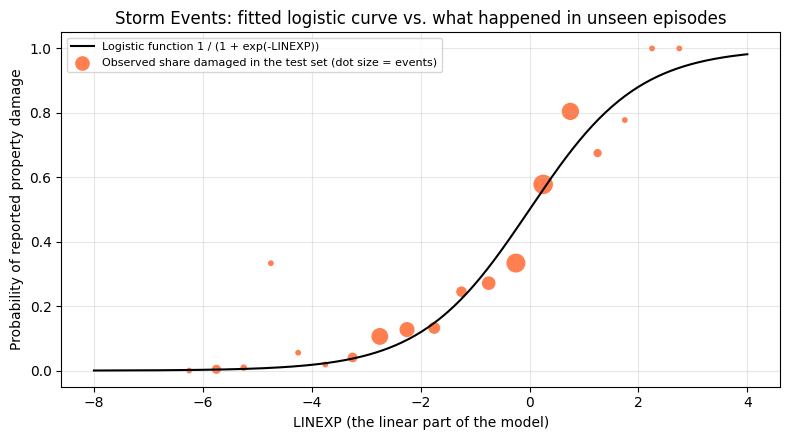

Test events with the largest cross-entropy loss:
              EVENT_TYPE          STATE WFO  durationHours  damaged  prob  loss
              Heavy Rain AMERICAN SAMOA ASO         31.000        1 0.003 5.683
Marine Thunderstorm Wind  LAKE SUPERIOR DLH          0.283        1 0.005 5.368
              Heavy Rain        ARIZONA TWC          0.167        1 0.009 4.711
       Thunderstorm Wind  MASSACHUSETTS BOX        216.000        0 0.990 4.603
                   Flood     CALIFORNIA HNX          0.000        1 0.013 4.357
             Debris Flow     CALIFORNIA HNX          0.000        1 0.015 4.193


In [6]:
Z = StandardScaler().fit_transform(data[features])
vif = pd.Series(np.diag(np.linalg.inv(np.corrcoef(Z, rowvar=False))), index=features).round(2)
print('Variance inflation factors:')
print(vif.sort_values(ascending=False).to_string())

def event_model():
    # Numeric inputs standardized, event-type indicators left as 0/1 so their odds ratios read as yes vs. no
    prep = ColumnTransformer([('num', StandardScaler(), numeric), ('types', 'passthrough', type_cols)])
    return Pipeline([('prep', prep), ('lr', LogisticRegression(max_iter=3000))])

base = event_model().fit(train[features], y_train)
linexp = base.decision_function(test[features])
prob = 1 / (1 + np.exp(-linexp))
bins = pd.cut(linexp, np.arange(-8, 4.5, 0.5))
observed = pd.Series(y_test).groupby(bins, observed=True).agg(['mean', 'size'])

fig, ax = plt.subplots(figsize=(8, 4.5))
grid_x = np.linspace(-8, 4, 300)
ax.plot(grid_x, 1 / (1 + np.exp(-grid_x)), color='black', label='Logistic function 1 / (1 + exp(-LINEXP))')
ax.scatter([b.mid for b in observed.index], observed['mean'], s=np.clip(observed['size'] / 8, 10, 300),
           color='coral', label='Observed share damaged in the test set (dot size = events)')
ax.set_xlabel('LINEXP (the linear part of the model)')
ax.set_ylabel('Probability of reported property damage')
ax.set_title('Storm Events: fitted logistic curve vs. what happened in unseen episodes')
ax.legend(loc='upper left', fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

per_event_loss = np.logaddexp(0, -(2 * y_test - 1) * linexp)
worst = test.assign(prob=prob, loss=per_event_loss).nlargest(6, 'loss')
print('Test events with the largest cross-entropy loss:')
print(worst[['EVENT_TYPE', 'STATE', 'WFO', 'durationHours', 'damaged', 'prob', 'loss']].round(3).to_string(index=False))

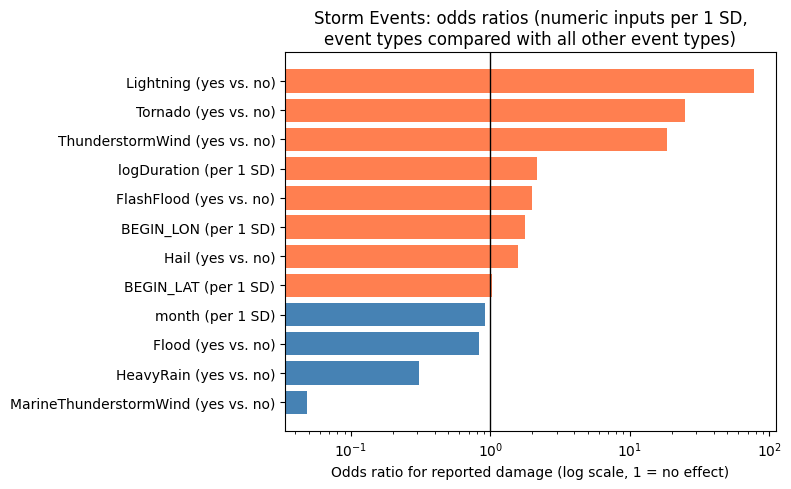

type_MarineThunderstormWind     0.049
type_HeavyRain                  0.307
type_Flood                      0.827
month                           0.910
BEGIN_LAT                       1.035
type_Hail                       1.573
BEGIN_LON                       1.781
type_FlashFlood                 1.992
logDuration                     2.155
type_ThunderstormWind          18.566
type_Tornado                   25.048
type_Lightning                 77.142


In [7]:
coef = pd.Series(base['lr'].coef_[0], index=features)
odds = np.exp(coef).sort_values()
labels = [f + (' (yes vs. no)' if f.startswith('type_') else ' (per 1 SD)') for f in odds.index]
labels = [l.replace('type_', '') for l in labels]

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(labels, odds.values, color=np.where(odds.values > 1, 'coral', 'steelblue'))
ax.axvline(1, color='black', linewidth=1)
ax.set_xscale('log')
ax.set_xlabel('Odds ratio for reported damage (log scale, 1 = no effect)')
ax.set_title('Storm Events: odds ratios (numeric inputs per 1 SD,\nevent types compared with all other event types)')
plt.tight_layout()
plt.show()
print(odds.round(3).to_string())

The VIFs are high for the event-type indicators, up to 12.1 for thunderstorm wind and 9.5 for hail, while latitude, longitude, and month are all close to 1. This is the lesson's multicollinearity problem in a mild form. Because nearly every event belongs to one of the eight types, knowing seven of the indicators almost tells you the eighth, and the only thing keeping them apart is the small baseline group. The predictions are fine, but each event-type coefficient is a comparison with that baseline, which is 694 mostly harmless events (funnel clouds, debris flows, waterspouts) that report damage only 7% of the time.

That explains why the odds ratios on the chart look so extreme. Lightning's 77 and tornado's 25 do not mean lightning is 77 times as dangerous as anything else. They mean the odds of reported damage for a lightning event are about 77 times the odds for an event in the baseline group. Hail (1.57) and marine thunderstorm wind (0.049) sit at the low end, which matches the raw rates, since hail reports damage on 8% of events and marine thunderstorm wind on 0.1%. Among the numeric features, log duration has the largest effect (an odds ratio of 2.16 per standard deviation), followed by longitude (1.78), so longer events and events farther east are more likely to report damage.

Unlike the NFIP model, this one is well calibrated. The observed share of damaged events follows the logistic curve closely in nearly every LINEXP bin with a meaningful number of events, even on episodes the model never saw.

The worst-loss table shows what the lesson means by outlier sensitivity. A cross-entropy loss of 5.7 means the model gave the true outcome a probability of only 0.003. Several of these cases look like data problems more than modeling ones. One thunderstorm wind in Massachusetts is recorded as lasting 216 hours, about nine days, when the typical thunderstorm wind report has the same start and end time. That long duration pushed its predicted probability of damage to 0.99, and no damage was reported. Others are rare combinations, such as heavy rain damage in American Samoa, that a model with eight event types and four numeric features has no way to anticipate.

### Adding the reporting office, and regularization

So far the model ignores the National Weather Service office (WFO) that wrote up each event. Offices differ a lot in how often they fill in a damage estimate, so the office could carry predictive signal that has nothing to do with the weather. Adding it as one-hot indicators, with offices that have fewer than 30 events grouped together, adds about 100 columns, and that is where regularization starts to matter. I chose C with a validation curve, using 5-fold `GroupKFold` by episode and log loss as the score.

Validation curve took 21 seconds
     C  Training log loss  Grouped CV log loss    Gap
 0.001             0.5378               0.5422 0.0043
 0.003             0.4960               0.5020 0.0060
 0.010             0.4439               0.4526 0.0087
 0.030             0.3967               0.4083 0.0116
 0.100             0.3590               0.3735 0.0144
 0.300             0.3413               0.3578 0.0165
 1.000             0.3339               0.3523 0.0184
 3.000             0.3320               0.3515 0.0195
10.000             0.3314               0.3518 0.0204
Best C by grouped cross-validation: 3.0


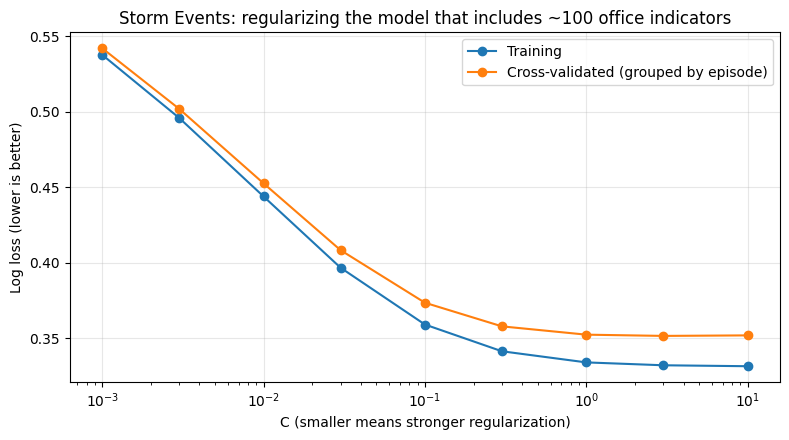

In [8]:
def office_model(C=1.0):
    prep = ColumnTransformer([('num', StandardScaler(), numeric),
                              ('types', 'passthrough', type_cols),
                              ('office', OneHotEncoder(handle_unknown='ignore', min_frequency=30), ['WFO'])])
    return Pipeline([('prep', prep), ('lr', LogisticRegression(C=C, max_iter=3000))])

C_range = [0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1, 3, 10]
t0 = time.time()
tr_scores, cv_scores = validation_curve(office_model(), train, y_train, param_name='lr__C', param_range=C_range,
                                        groups=g_train, cv=GroupKFold(n_splits=5),
                                        scoring='neg_log_loss', n_jobs=-1)
print(f'Validation curve took {time.time() - t0:.0f} seconds')
curve = pd.DataFrame({'C': C_range, 'Training log loss': -tr_scores.mean(axis=1),
                      'Grouped CV log loss': -cv_scores.mean(axis=1)})
curve['Gap'] = curve['Grouped CV log loss'] - curve['Training log loss']
print(curve.round(4).to_string(index=False))
best_C = curve.loc[curve['Grouped CV log loss'].idxmin(), 'C']
print('Best C by grouped cross-validation:', best_C)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.semilogx(curve['C'], curve['Training log loss'], marker='o', label='Training')
ax.semilogx(curve['C'], curve['Grouped CV log loss'], marker='o', label='Cross-validated (grouped by episode)')
ax.set_xlabel('C (smaller means stronger regularization)')
ax.set_ylabel('Log loss (lower is better)')
ax.set_title('Storm Events: regularizing the model that includes ~100 office indicators')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Office indicators in the model: 106
Office odds ratios range from 0.005 to 164.8
For comparison, event-type odds ratios in the same model range from 0.025 to 353.6


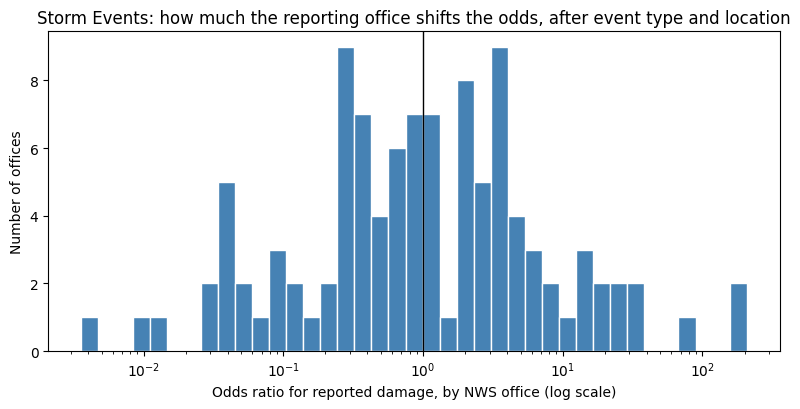

In [9]:
with_office = office_model(best_C).fit(train, y_train)
office_coefs = pd.Series(with_office['lr'].coef_[0], index=with_office['prep'].get_feature_names_out())
office_coefs = office_coefs[office_coefs.index.str.startswith('office__')]
print('Office indicators in the model:', len(office_coefs))
print(f'Office odds ratios range from {np.exp(office_coefs.min()):.3f} to {np.exp(office_coefs.max()):.1f}')
print('For comparison, event-type odds ratios in the same model range from',
      f"{np.exp(with_office['lr'].coef_[0][len(numeric):len(features)]).min():.3f} to "
      f"{np.exp(with_office['lr'].coef_[0][len(numeric):len(features)]).max():.1f}")

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.hist(np.exp(office_coefs), bins=np.logspace(office_coefs.min() / np.log(10) - 0.1, office_coefs.max() / np.log(10) + 0.1, 40),
        color='steelblue', edgecolor='white')
ax.set_xscale('log')
ax.axvline(1, color='black', linewidth=1)
ax.set_xlabel('Odds ratio for reported damage, by NWS office (log scale)')
ax.set_ylabel('Number of offices')
ax.set_title('Storm Events: how much the reporting office shifts the odds, after event type and location')
plt.tight_layout()
plt.show()

### Final evaluation on held-out storm episodes

In [10]:
p_base = base.predict_proba(test[features])[:, 1]
p_office = with_office.predict_proba(test)[:, 1]
p_majority = np.full(len(y_test), y_train.mean())
base_rate = y_train.mean()
results = pd.DataFrame([
    scores('Majority class (predicts the base rate)', y_test, p_majority),
    scores('Event features, threshold 0.5', y_test, p_base),
    scores(f'Event features, threshold {base_rate:.2f} (base rate)', y_test, p_base, threshold=base_rate),
    scores(f'Event features + office, tuned C = {best_C}', y_test, p_office),
])
print('Test events (unseen episodes):', len(y_test))
print(results.round(3).to_string(index=False))

# Same two models with an ordinary random split, for comparison
r_tr, r_te = train_test_split(np.arange(len(y)), test_size=0.25, stratify=y, random_state=0)
rand_base = event_model().fit(data.iloc[r_tr][features], y[r_tr])
rand_office = office_model(best_C).fit(data.iloc[r_tr], y[r_tr])
print()
print('Test ROC-AUC, random split vs. split by episode:')
print(pd.DataFrame({'Random split': [roc_auc_score(y[r_te], rand_base.predict_proba(data.iloc[r_te][features])[:, 1]),
                                     roc_auc_score(y[r_te], rand_office.predict_proba(data.iloc[r_te])[:, 1])],
                    'Split by episode': [roc_auc_score(y_test, p_base), roc_auc_score(y_test, p_office)]},
                   index=['Event features', 'Event features + office']).round(4).to_string())

Test events (unseen episodes): 7961
                                     Model  Accuracy  Balanced acc.    F1  Log loss  ROC-AUC
   Majority class (predicts the base rate)     0.651          0.500 0.000     0.647    0.500
             Event features, threshold 0.5     0.772          0.744 0.666     0.498    0.821
Event features, threshold 0.35 (base rate)     0.710          0.738 0.666     0.498    0.821
    Event features + office, tuned C = 3.0     0.851          0.831 0.781     0.361    0.909



Test ROC-AUC, random split vs. split by episode:
                         Random split  Split by episode
Event features                 0.8268            0.8212
Event features + office        0.9155            0.9095


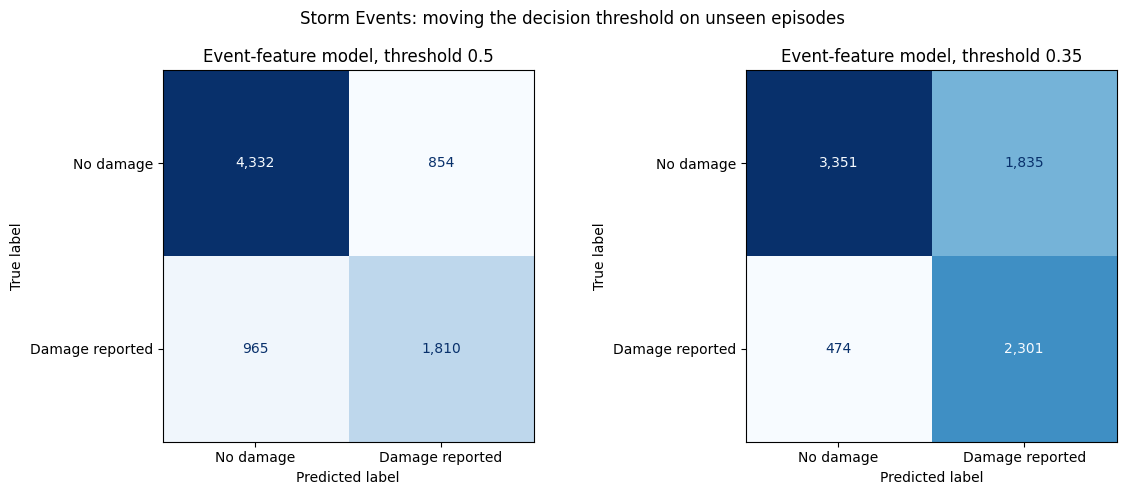

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, thr, title in [(axes[0], 0.5, 'threshold 0.5'), (axes[1], base_rate, f'threshold {base_rate:.2f}')]:
    ConfusionMatrixDisplay.from_predictions(y_test, (p_base >= thr).astype(int),
                                            display_labels=['No damage', 'Damage reported'],
                                            cmap='Blues', values_format=',', ax=ax, colorbar=False)
    ax.set_title(f'Event-feature model, {title}')
fig.suptitle('Storm Events: moving the decision threshold on unseen episodes')
plt.tight_layout()
plt.show()

## Discussion

### Overfitting

There are two kinds of overfitting to watch for here. The first is the usual kind, where the model has too many parameters for the data. The base model has only 12 features, so that is not a concern for it, but the office model adds 106 indicators, and the validation curve shows the penalty doing its job. Cross-validated log loss drops from 0.542 at C = 0.001 to its best value of 0.3515 at C = 3 and then ticks back up to 0.3518 at C = 10, while the gap between training and cross-validated loss widens steadily from 0.004 to 0.020 as C grows. The curve is very flat between C = 1 and C = 10, so the exact choice is not critical, but strong penalties clearly underfit.

The second kind is leakage between related rows, which ties back to the lesson's point about independent samples. Splitting by episode keeps the model from being scored on sibling events of storms it trained on. For logistic regression this made less difference than I expected. The base model scores 0.827 under a random split and 0.821 split by episode, and the office model scores 0.916 and 0.910. A model made of a few straight-line coefficients cannot memorize individual storms the way a more flexible model can. Where clustering does matter is in the uncertainty of the coefficients. The episode bootstrap showed their variances are about 4.4 times larger than they look when events are treated as independent.

### Metrics and hyperparameter tuning

Log loss was the tuning metric because it is the cross-entropy loss that logistic regression minimizes, and it judges the probabilities themselves instead of a single cutoff. Only 35% of events report damage, so accuracy alone is misleading, since always predicting no damage already scores 0.651 with an F1 of zero. The test results add balanced accuracy, F1, and ROC-AUC.

The one model setting tuned here is C for the office model, and grouped cross-validation chose C = 3. The base model keeps the default C = 1. The scaling experiment showed that once features are standardized, even C = 0.01 barely changes its ROC-AUC (0.821 to 0.820), so there was little to tune.

The decision threshold is a second setting worth tuning, separate from the model. At the default of 0.5 the base model catches 1,810 of the 2,775 damaging test events (65%) with 854 false alarms. Lowering the threshold to the base rate of 0.35 catches 2,301 (83%) but raises false alarms to 1,835. Accuracy falls from 0.772 to 0.710 and F1 stays at 0.666, so neither threshold is better in general. The right one depends on whether a missed damaging event or a false alarm costs more, for example when deciding which events need a damage survey.

With the office added and C = 3, the model reaches 0.851 accuracy, 0.831 balanced accuracy, 0.781 F1, 0.361 log loss, and 0.909 ROC-AUC on unseen episodes, up from 0.821 ROC-AUC for the base model.

### Expected or unexpected

I expected event type to carry most of the signal, and it does. What I did not expect was how much the reporting office added on top of it. Adding the office lifted ROC-AUC on unseen episodes from 0.821 to 0.909, a bigger jump than anything else in this notebook. Even after event type and location are accounted for, the office odds ratios range from 0.005 to 164.8, which seems far too wide to be about weather alone. It looks like some offices almost always enter a damage estimate and others rarely do. That makes the office a strong predictor of the damage field but not necessarily of damage itself, and it would mislead anyone reading those coefficients as physical effects.

The size of the event-type odds ratios also surprised me at first, until the VIFs pointed to the small baseline group. And I expected the episode structure to change the test score more than it did. It mattered a lot for the uncertainty of the coefficients and very little for prediction, at least for a model this simple.

The 216-hour thunderstorm wind was a useful reminder that the largest losses often point to data errors. Logistic regression has no protection against a bad input, because LINEXP is linear in every feature and the loss grows along with LINEXP once the model is confidently wrong.

### How EDA helped

The Module B EDA showed that property damage is extremely right-skewed, which is why this notebook predicts whether damage was reported instead of the amount. The table of raw scales showed durations from 0 to almost 744 hours with more than half of events at zero, which is why duration is log-transformed, and the scaling experiment confirmed that it helps (0.813 to 0.821). The episode check, which found 64% of multi-event episodes sharing one damage label, is what led to the grouped split, the grouped cross-validation, and the episode bootstrap. And the minimum and maximum latitudes (American Samoa and Alaska) explained why min-max scaling squeezed latitude so badly under a penalty.

EDA also explained the odds ratios after the fact. Looking at what was left in the baseline group, mostly funnel clouds and waterspouts with a 7% damage rate, made it clear why the event-type coefficients came out so large.

### External sources

- scikit-learn User Guide, "Logistic regression" (in the Linear Models chapter): https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
- scikit-learn example, "Importance of Feature Scaling": https://scikit-learn.org/stable/auto_examples/preprocessing/plot_scaling_importance.html
- scikit-learn User Guide, "Cross-validation: evaluating estimator performance," the section on cross-validation for grouped data (`GroupKFold`, `GroupShuffleSplit`): https://scikit-learn.org/stable/modules/cross_validation.html
- Cameron and Miller, "A Practitioner's Guide to Cluster-Robust Inference," *Journal of Human Resources* 50(2), 2015, on why clustered data makes ordinary standard errors too small.
- National Weather Service Instruction 10-1605, *Storm Data Preparation*, for how forecast offices group events into episodes and enter damage estimates.


### Conclusions

Using event type, location, month, and duration, logistic regression predicts whether a 2017 point-located storm event had property damage reported with a test ROC-AUC of 0.821 on storms it never saw, and it is well calibrated, so its probabilities can be read at face value. Standardizing the numeric features cut the solver's iterations by a factor of 25 to 46 and kept the penalty fair, and log-transforming duration helped more than any choice of scaler. Adding the reporting office raises ROC-AUC to 0.909, but that gain says more about how offices fill in the damage field than about the storms.

For the Capstone, the main lessons from this notebook are about independence and interpretation. Storm events are clustered by episode, so the coefficients need episode-level uncertainty, and odds ratios for event types only make sense next to the baseline they are compared with. Logistic regression is a solid, readable baseline for this data, but any model that includes the office should be presented as predicting what gets recorded, not the damage itself.